# Steam games: initial data exploration

**Group 23: Forecasting Commercial Success of a Steam Game**

**Data:** `games.csv` from (https://www.kaggle.com/datasets/fronkongames/steam-games-dataset)
(Fronkon Games, version 55, updated Oct 20, 2026). The file is about 400 MB and is **not** in the repo. The loader
looks for it at `data/games.csv`, `../data/games.csv` or `../../games.csv` (relative to this notebook).

Load the data:

- The CSV header has 39 names but every data row has 40 fields, because `Discount` and `DLC count`
are fused into one header name, `DiscountDLC count`.

In [1]:
from pathlib import Path
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

%matplotlib inline
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

BLUE, ORANGE, GRAY = "#4C78A8", "#E8763C", "#B8B8B8"

THRESHOLD = 100_000                          # hit = lower end of owners range >= THRESHOLD
SNAPSHOT_DATE = pd.Timestamp("2026-10-20")   # date of the Kaggle version we downloaded

TARGET = "Estimated owners"
COLUMN_GROUPS = {
    "id":          ["AppID", "Name"],
    "store":       ["Price", "Discount", "DLC count", "Required age", "Achievements"],
    "platform":    ["Windows", "Mac", "Linux"],
    "release":     ["Release date"],
    "multi-label": ["Genres", "Categories", "Tags", "Supported languages", "Full audio languages"],
    "studio":      ["Developers", "Publishers"],
    "engagement":  ["Peak CCU", "Positive", "Negative", "Recommendations",
                    "Average playtime forever", "Average playtime two weeks",
                    "Median playtime forever", "Median playtime two weeks",
                    "Metacritic score", "User score", "Score rank"],
    "text/url":    ["About the game", "Notes", "Reviews", "Header image", "Screenshots", "Movies",
                    "Website", "Support url", "Support email", "Metacritic url"],
}
GROUP_OF = {col: group for group, cols in COLUMN_GROUPS.items() for col in cols}

In [2]:
CANDIDATES = [Path("data/games.csv"), Path("../data/games.csv"), Path("../../games.csv")]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert CSV_PATH is not None, "games.csv not found. Put it at one of: " + ", ".join(map(str, CANDIDATES))

with open(CSV_PATH, encoding="utf-8", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)
    first_row = next(reader)

if len(first_row) == len(header) + 1 and "DiscountDLC count" in header:
    i = header.index("DiscountDLC count")
    header[i:i + 1] = ["Discount", "DLC count"]
    df = pd.read_csv(CSV_PATH, names=header, skiprows=1, low_memory=False)
    print("Fixed the fused 'DiscountDLC count' header.")
elif len(first_row) == len(header):
    df = pd.read_csv(CSV_PATH, low_memory=False)
else:
    raise ValueError(f"Unexpected header: {len(header)} names vs {len(first_row)} fields. Inspect manually.")

RAW_COLS = list(df.columns)
unexpected = set(RAW_COLS) - set(GROUP_OF) - {TARGET}
assert not unexpected, f"Columns not in COLUMN_GROUPS: {unexpected}"

print(f"Loaded {CSV_PATH}: {df.shape[0]:,} rows x {df.shape[1]} columns ({df.shape[1] - 1} besides the target)")

Fixed the fused 'DiscountDLC count' header.
Loaded ..\..\games.csv: 125,855 rows x 40 columns (39 besides the target)


In [3]:
# Parse the release date once; used in several sections below.
df["release_date"] = pd.to_datetime(df["Release date"], format="mixed", errors="coerce")
df["release_year"] = df["release_date"].dt.year
print("Unparsed release dates:", df["release_date"].isna().sum())
print("Release dates range from", df["release_date"].min().date(), "to", df["release_date"].max().date())

Unparsed release dates: 0
Release dates range from 1997-06-30 to 2026-12-01


In [4]:
df[RAW_COLS].sample(5, random_state=42)

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,Supported languages,Full audio languages,Reviews,Header image,Website,Support url,Support email,Windows,Mac,Linux,Metacritic score,Metacritic url,User score,Positive,Negative,Score rank,Achievements,Recommendations,Notes,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
127,3400080,Fantasy Soul Revenge,"Dec 28, 2024",0 - 20000,0,0,0.69,0,0,Fantasy Soul Revenge - Explore Your Fighting Skills Beat...,"['English', 'French', 'Italian', 'German', 'Spanish - Sp...",[],NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN,NaN,nitin.javapro@gmail.com,True,False,False,0,NaN,0,4,2,NaN,0,0,NaN,0,0,0,0,Nitx Games,Nitx Games,"Single-player,Family Sharing","Action,Casual,Indie,Simulation,Strategy","Side Scroller,Action,Beat 'em up,2D Fighter,Arcade,Actio...",https://shared.akamai.steamstatic.com/store_item_assets/...,NaN
67814,2554950,Raioh,"Oct 6, 2023",0 - 20000,0,0,3.49,50,0,Raioh is a retro style shot and bomb style vertical scro...,['English'],[],NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN,NaN,ontake44@gmail.com,True,False,False,0,NaN,0,17,0,NaN,0,0,NaN,0,0,0,0,Ontake Workshop,Ontake Workshop,"Single-player,Partial Controller Support,Family Sharing",Action,"Action,Shooter,Shoot 'Em Up,Singleplayer,2D,Pixel Graphi...",https://shared.akamai.steamstatic.com/store_item_assets/...,NaN
29650,4025190,Ten Tek,"Oct 18, 2025",0 - 0,0,0,1.59,0,0,TenTek is an atmospheric mystical game where you take on...,"['English', 'Russian']","['English', 'Russian']",NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN,NaN,lgcompanymonitors@gmail.com,True,False,False,0,NaN,0,0,0,NaN,0,118,The game contains scenes of full nudity and explicit sex...,0,0,0,0,Inspite,Inspite,"Single-player,Family Sharing","Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN
104535,472770,HELP: THE GAME,"Jul 26, 2016",0 - 20000,0,0,14.99,0,0,HELP: The Game is a project which brings together the to...,['English'],['English'],NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,https://warchildgaming.org.uk/campaign/help-pc-mobile/,https://warchildgaming.org.uk/campaign/help-pc-mobile/,NaN,True,False,False,0,NaN,0,9,0,NaN,0,0,NaN,0,0,0,0,"Sports Interactive,Creative Assembly,Rovio Sweden AB,Tor...",War Child Gaming,"Single-player,Multi-player,Partial Controller Support,Fa...",Indie,Indie,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN
51049,4129210,Hentai Travel,"Nov 21, 2025",0 - 0,0,0,2.99,0,0,Hentai Travel - Solve puzzles of varying difficulty. The...,"['English', 'French', 'Italian', 'German', 'Spanish - Sp...",[],NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN,NaN,uwuGameDEVelop@gmail.com,True,False,False,0,NaN,0,0,0,NaN,30,0,-Nudity sexual content -Not suitable for all ages -All c...,0,0,0,0,UwU,UwU,"Single-player,Steam Achievements,Full controller support...","Casual,Indie",NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN


### Column overview

One row per column: its group, data type, how much is missing, how many distinct values, and an example value.

In [5]:
def example_value(col):
    values = df[col].dropna().astype(str)
    values = values[values.str.len() > 0]
    return values.iloc[0][:50] if len(values) else ""

overview = pd.DataFrame({
    "group":     [GROUP_OF.get(c, "TARGET") for c in RAW_COLS],
    "dtype":     df[RAW_COLS].dtypes.astype(str).values,
    "non_null":  df[RAW_COLS].notna().sum().values,
    "missing_%": (df[RAW_COLS].isna().mean() * 100).round(1).values,
    "n_unique":  df[RAW_COLS].nunique().values,
    "example":   [example_value(c) for c in RAW_COLS],
}, index=RAW_COLS)

group_order = ["TARGET"] + list(COLUMN_GROUPS)
overview = overview.sort_values("group", key=lambda s: s.map(group_order.index), kind="stable")
overview

,group,dtype,non_null,missing_%,n_unique,example
Estimated owners,TARGET,str,125855,0.0,14,0 - 0
AppID,id,int64,125855,0.0,125855,2539430
Name,id,str,125854,0.0,124644,Black Dragon Mage Playtest
Required age,store,int64,125855,0.0,15,0
Price,store,float64,125855,0.0,953,0.0
Discount,store,int64,125855,0.0,88,0
DLC count,store,int64,125855,0.0,117,0
Achievements,store,int64,125855,0.0,449,0
Windows,platform,bool,125855,0.0,2,True
Mac,platform,bool,125855,0.0,2,False


### Summary statistics 

In [6]:
numeric_cols = COLUMN_GROUPS["store"] + COLUMN_GROUPS["engagement"]
df[numeric_cols].describe(percentiles=[0.5, 0.9, 0.99]).T.round(2)

,count,mean,std,min,50%,90%,99%,max
Price,125855.0,4.81,12.49,0.0,2.39,9.99,29.99,999.98
Discount,125855.0,17.90,28.63,0.0,0.00,70.00,90.00,100.00
DLC count,125855.0,0.54,14.33,0.0,0.00,1.00,7.00,3703.00
Required age,125855.0,0.17,1.64,0.0,0.00,0.00,10.00,21.00
Achievements,125855.0,17.92,139.70,0.0,2.00,38.00,100.00,9821.00
Peak CCU,125855.0,53.19,3681.08,0.0,0.00,2.00,215.46,1013936.00
Positive,125855.0,1018.18,27727.82,0.0,4.00,276.00,12869.52,7642084.00
Negative,125855.0,164.88,5305.00,0.0,1.00,68.00,2068.00,1173003.00
Recommendations,125855.0,938.04,21595.85,0.0,0.00,290.00,12066.68,4830455.00
Average playtime forever,125855.0,202.76,11072.22,0.0,0.00,227.00,2221.00,3429544.00


Almost every numeric column is heavily right-skewed. The median is 0 or close to it, while the maximum is huge. Models that are sensitive to scale will need a log transform and/or scaling.

4. Target variable: `Estimated owners`

SteamSpy's estimate of how many Steam accounts own the game, stored as a text range such as `"20000 - 50000"`.
We parse out both ends of the range.

In [7]:
bounds = df[TARGET].astype(str).str.extract(r"(\d+)\s*-\s*(\d+)").astype(float)
df["owners_low"], df["owners_high"] = bounds[0], bounds[1]
print("Rows that didn't parse:", df["owners_low"].isna().sum())

def short(n):
    n = float(n)
    if n >= 1e6: return f"{n / 1e6:g}M"
    if n >= 1e3: return f"{n / 1e3:g}K"
    return f"{n:g}"

ranges = (df.groupby(["owners_low", "owners_high"]).size().rename("games").reset_index())
ranges["range"] = [f"{short(lo)}–{short(hi)}" for lo, hi in zip(ranges["owners_low"], ranges["owners_high"])]
ranges["% of games"] = (ranges["games"] / len(df) * 100).round(2)
ranges[["range", "games", "% of games"]]

Rows that didn't parse: 0


,range,games,% of games
0,0–0,24579,19.53
1,0–20K,75705,60.15
2,20K–50K,11397,9.06
3,50K–100K,5355,4.25
4,100K–200K,3454,2.74
5,200K–500K,2856,2.27
6,500K–1M,1155,0.92
7,1M–2M,729,0.58
8,2M–5M,405,0.32
9,5M–10M,125,0.10


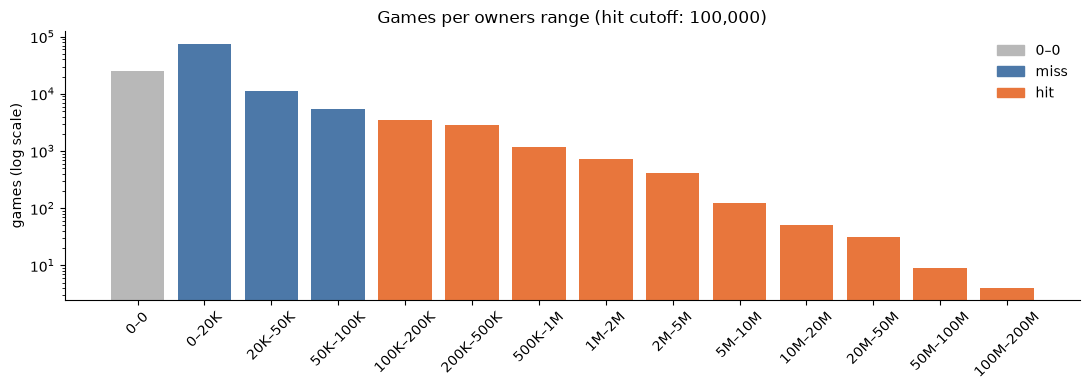

In [8]:
def range_color(lo, hi):
    if lo == 0 and hi == 0:
        return GRAY
    return ORANGE if lo >= THRESHOLD else BLUE

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(ranges["range"], ranges["games"],
       color=[range_color(lo, hi) for lo, hi in zip(ranges["owners_low"], ranges["owners_high"])])
ax.set_yscale("log")
ax.set_ylabel("games (log scale)")
ax.set_title(f"Games per owners range (hit cutoff: {THRESHOLD:,})")
ax.tick_params(axis="x", rotation=45)
ax.legend(handles=[Patch(color=GRAY, label="0–0"),
                   Patch(color=BLUE, label="miss"), Patch(color=ORANGE, label="hit")], frameon=False)
plt.tight_layout()
plt.show()

In [9]:
df["no_owner_data"] = (df["owners_low"] == 0) & (df["owners_high"] == 0)
df["hit"] = (df["owners_low"] >= THRESHOLD).astype(int)

counts = pd.DataFrame({
    "all rows": df["hit"].value_counts(),
    "excluding 0–0 rows": df.loc[~df["no_owner_data"], "hit"].value_counts(),
}).rename(index={0: "miss (0)", 1: "hit (1)"})
pd.concat({"games": counts, "%": (counts / counts.sum() * 100).round(1)}, axis=1)

games                           %                   
         all rows excluding 0–0 rows all rows excluding 0–0 rows
hit                                                             
miss (0)   117036              92457     93.0               91.3
hit (1)      8819               8819      7.0                8.7

In [10]:
known_rows = ~df["no_owner_data"]
options = []
for t in [50_000, 100_000, 200_000, 500_000, 1_000_000]:
    is_hit = df.loc[known_rows, "owners_low"] >= t
    options.append({"hit if owners_low >=": f"{t:,}", "hits": int(is_hit.sum()),
                    "hit % (excl. 0–0)": round(is_hit.mean() * 100, 1)})
pd.DataFrame(options)

,hit if owners_low >=,hits,hit % (excl. 0–0)
0,"50,000",14174,14.0
1,"100,000",8819,8.7
2,"200,000",5365,5.3
3,"500,000",2509,2.5
4,"1,000,000",1354,1.3


With the working cutoff of 100K, about 7% of all games are hits, so a model that always answers "miss" would be over 90% accurate. So we'll need a
stratified train/test split

## Missing values and duplicates


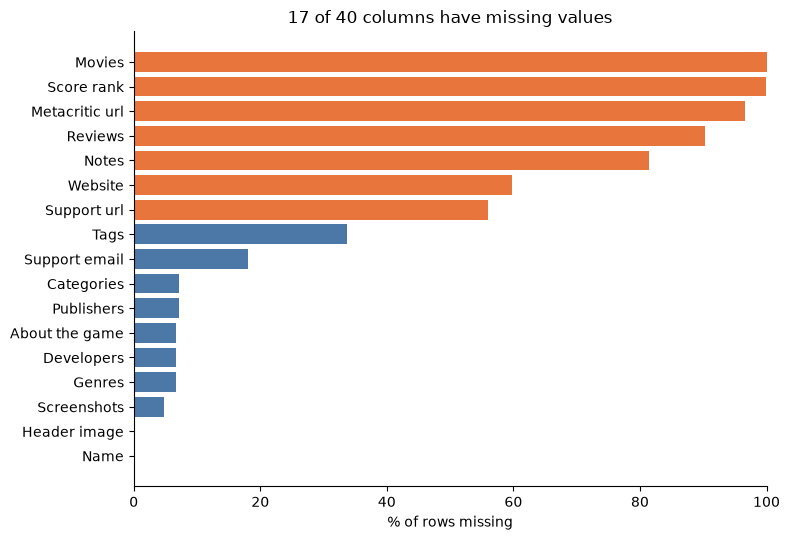

In [11]:
missing = (df[RAW_COLS].isna().mean() * 100).sort_values()
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(missing.index, missing.values,
        color=[ORANGE if v > 50 else BLUE for v in missing.values])
ax.set_xlabel("% of rows missing")
ax.set_title(f"{len(missing)} of {len(RAW_COLS)} columns have missing values")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

### "Hidden" missing values

Some columns use 0 or an empty list `[]` instead of a blank. Some zeros are real (free games have a price of 0), but a
Metacritic score or User score of 0 means "no score".

In [12]:
zero_share = ((df[numeric_cols] == 0).mean() * 100).round(1).sort_values(ascending=False).rename("% zero")
empty_lists = pd.Series({c: round((df[c].fillna("[]").str.strip() == "[]").mean() * 100, 1)
                         for c in ["Supported languages", "Full audio languages"]}, name="% empty list")
display(zero_share.to_frame())
display(empty_lists.to_frame())

,% zero
User score,100.0
Required age,99.0
Average playtime two weeks,96.9
Median playtime two weeks,96.9
Metacritic score,96.6
DLC count,85.7
Peak CCU,84.4
Recommendations,83.3
Median playtime forever,79.2
Average playtime forever,79.2


,% empty list
Supported languages,6.7
Full audio languages,59.3


### Duplicates

In [13]:
print("Duplicate rows:  ", df[RAW_COLS].duplicated().sum())
print("Duplicate AppIDs:", df["AppID"].duplicated().sum())
print("Repeated names:  ", df["Name"].duplicated().sum())
df["Name"].value_counts().head(8).rename("store entries with this name")

Duplicate rows:   0
Duplicate AppIDs: 0
Repeated names:   1210


Name
Shadow of the Tomb Raider: Definitive Edition    20
Escape                                            6
Loop                                              5
Gravity                                           5
Echoes                                            5
Echo                                              5
Tom Clancy's Rainbow Six® Siege X                 5
Trapped                                           5
Name: store entries with this name, dtype: int64

- `Movies` is completely empty, `Score rank` is almost empty, and `User score` is 0 for all but 40 games. Those three
  carry no information. `Metacritic score` is 0 (no score) for about 97% of games.
- The text and URL columns (`Reviews`, `Notes`, `Website`...) are often missing, but we don't plan to use them anyway.
- `Developers`, `Publishers`, `Genres` and `Categories` are each missing for about 7% of rows. Section 6 shows these are
  mostly playtests.
- No duplicate rows or AppIDs. About 1,200 names repeat with different AppIDs (editions or re-listings of the same
  title), which is worth a closer look.

## 6. Data-quality checks


In [14]:
df["is_playtest"] = df["Name"].str.contains("playtest", case=False, na=False)

def describe_rows(rows):
    return {
        "rows": len(rows),
        "% playtests": rows["is_playtest"].mean() * 100,
        "% missing Tags": rows["Tags"].isna().mean() * 100,
        "% missing Developers": rows["Developers"].isna().mean() * 100,
        "% with 0 positive reviews": (rows["Positive"] == 0).mean() * 100,
        "% released 2024 or later": (rows["release_year"] >= 2024).mean() * 100,
    }

pd.DataFrame({"0–0 rows": describe_rows(df[df["no_owner_data"]]),
              "all other rows": describe_rows(df[~df["no_owner_data"]])}).round(1)

,0–0 rows,all other rows
rows,24579.0,101276.0
% playtests,33.1,0.0
% missing Tags,100.0,17.7
% missing Developers,34.3,0.0
% with 0 positive reviews,100.0,20.7
% released 2024 or later,72.4,30.1


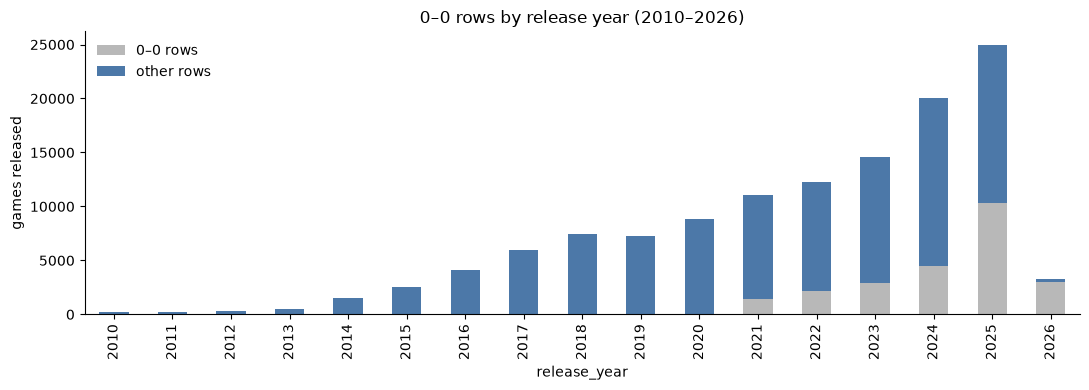

In [15]:
first_year, last_year = 2010, int(df["release_year"].max())
by_year = pd.DataFrame({
    "0–0 rows": df[df["no_owner_data"]].groupby("release_year").size(),
    "other rows": df[~df["no_owner_data"]].groupby("release_year").size(),
}).reindex(range(first_year, last_year + 1), fill_value=0)

ax = by_year.plot.bar(stacked=True, color=[GRAY, BLUE], figsize=(11, 4))
ax.set_ylabel("games released")
ax.set_title(f"0–0 rows by release year ({first_year}–{last_year})")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

`0 - 0` doesn't mean "nobody owns it", it means SteamSpy has no data for the game. Labeling these as misses would teach the model the wrong thing, so we propose dropping them.

### Unusual values

In [16]:
checks = pd.Series({
    f"release date after the snapshot ({SNAPSHOT_DATE.date()})": (df["release_date"] > SNAPSHOT_DATE).sum(),
    "price over $100": (df["Price"] > 100).sum(),
    "more than 1,000 achievements": (df["Achievements"] > 1000).sum(),
    "more than 100 DLCs": (df["DLC count"] > 100).sum(),
    "not available on Windows": (~df["Windows"]).sum(),
    "required age above 0": (df["Required age"] > 0).sum(),
}, name="games")
display(checks.to_frame())
display(df.nlargest(5, "Price")[["Name", "Price", TARGET]])
display(df.nlargest(5, "DLC count")[["Name", "DLC count", TARGET]])

,games
release date after the snapshot (2026-10-20),1
price over $100,317
"more than 1,000 achievements",159
more than 100 DLCs,39
not available on Windows,44
required age above 0,1288


,Name,Price,Estimated owners
41088,The Leverage Game Business Edition,999.98,0 - 20000
68275,The Leverage Game,999.98,0 - 20000
34463,Ascent Free-Roaming VR Experience,999.00,0 - 20000
31935,True Love,500.00,0 - 20000
77652,Aartform Curvy 3D 4.0,299.99,0 - 20000


,Name,DLC count,Estimated owners
122448,Fantasy Grounds VTT,3703,20000 - 50000
81495,Fantasy Grounds Classic,2006,100000 - 200000
97884,RPG Maker MV,1066,200000 - 500000
81801,Rocksmith® 2014 Edition REMASTERED LEARN & PLAY,967,500000 - 1000000
14969,RPG Maker MZ,875,200000 - 500000


The extreme values look like real listings (expensive software and VR packages, games with huge DLC catalogs) rather than typos, so a log transform or capping is a better fit than deleting rows.

## 7. Feature distributions

All rows. The multi-label columns are comma-separated text (`"Action,Indie"`), except the language columns, which look
like Python lists (`"['English', 'French']"`).

In [17]:
def split_labels(s):
    # "Action,Indie" -> ["Action", "Indie"]; missing -> []
    return s.fillna("").str.split(",").apply(lambda xs: [x.strip() for x in xs if x.strip()])

def split_languages(s):
    # "['English', 'French']" -> ["English", "French"]
    return (s.fillna("[]").str.strip("[]").str.split(",")
             .apply(lambda xs: [x.strip().strip("'\"") for x in xs if x.strip()]))

df["genre_list"] = split_labels(df["Genres"])
df["category_list"] = split_labels(df["Categories"])
df["tag_list"] = split_labels(df["Tags"])
df["language_list"] = split_languages(df["Supported languages"])
for col, count_col in [("genre", "n_genres"), ("category", "n_categories"), ("tag", "n_tags"), ("language", "n_languages")]:
    df[count_col] = df[f"{col}_list"].str.len()

pd.Series({col: df[f"{col}_list"].explode().nunique() for col in ["genre", "category", "tag", "language"]},
          name="distinct labels").to_frame()

,distinct labels
genre,33
category,58
tag,452
language,131


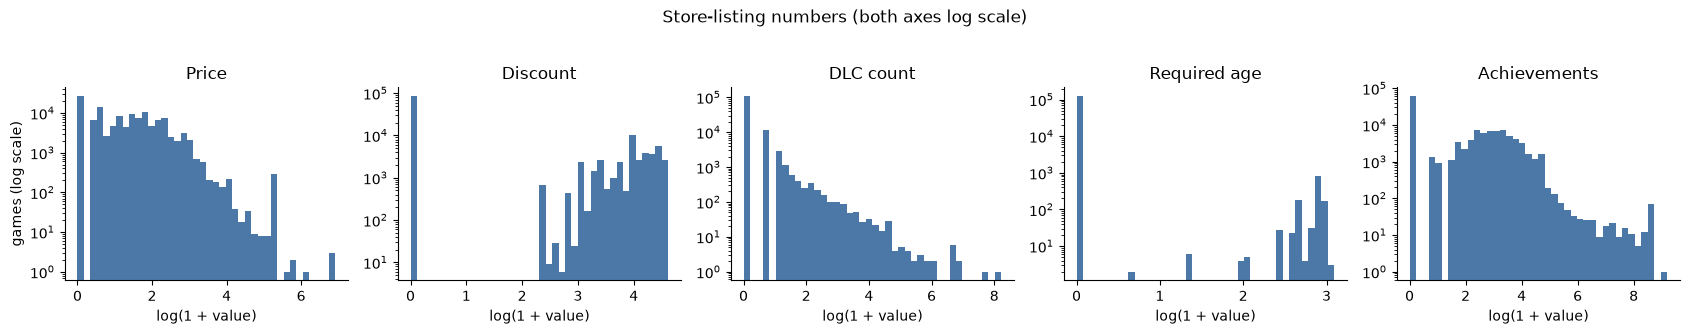

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.2))
for ax, col in zip(axes, COLUMN_GROUPS["store"]):
    ax.hist(np.log1p(df[col]), bins=40, color=BLUE)
    ax.set_title(col)
    ax.set_xlabel("log(1 + value)")
    ax.set_yscale("log")
axes[0].set_ylabel("games (log scale)")
plt.suptitle("Store-listing numbers (both axes log scale)", y=1.03)
plt.tight_layout()
plt.show()

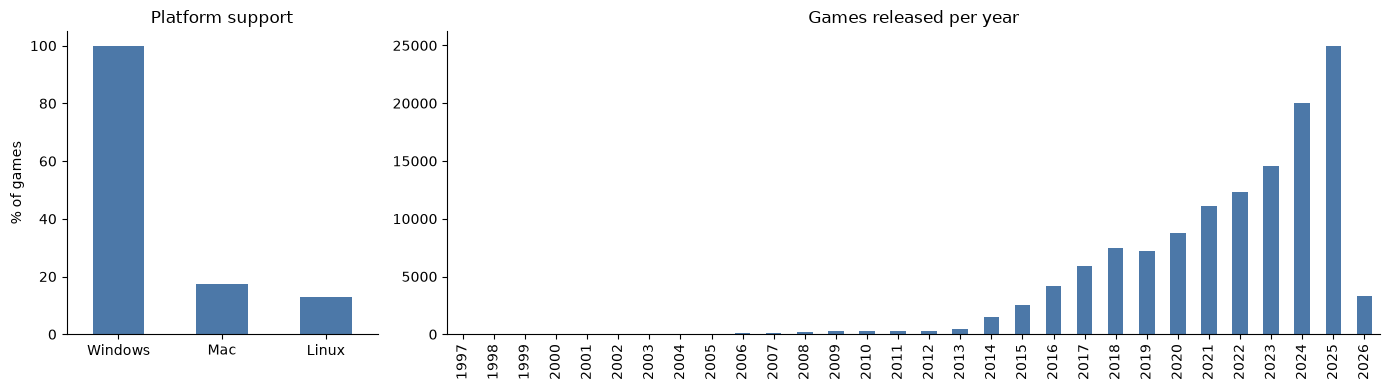

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 3]})
(df[COLUMN_GROUPS["platform"]].mean() * 100).plot.bar(ax=ax1, color=BLUE, rot=0)
ax1.set_ylabel("% of games")
ax1.set_title("Platform support")
df["release_year"].value_counts().sort_index().plot.bar(ax=ax2, color=BLUE)
ax2.set_title("Games released per year")
ax2.set_xlabel("")
plt.tight_layout()
plt.show()

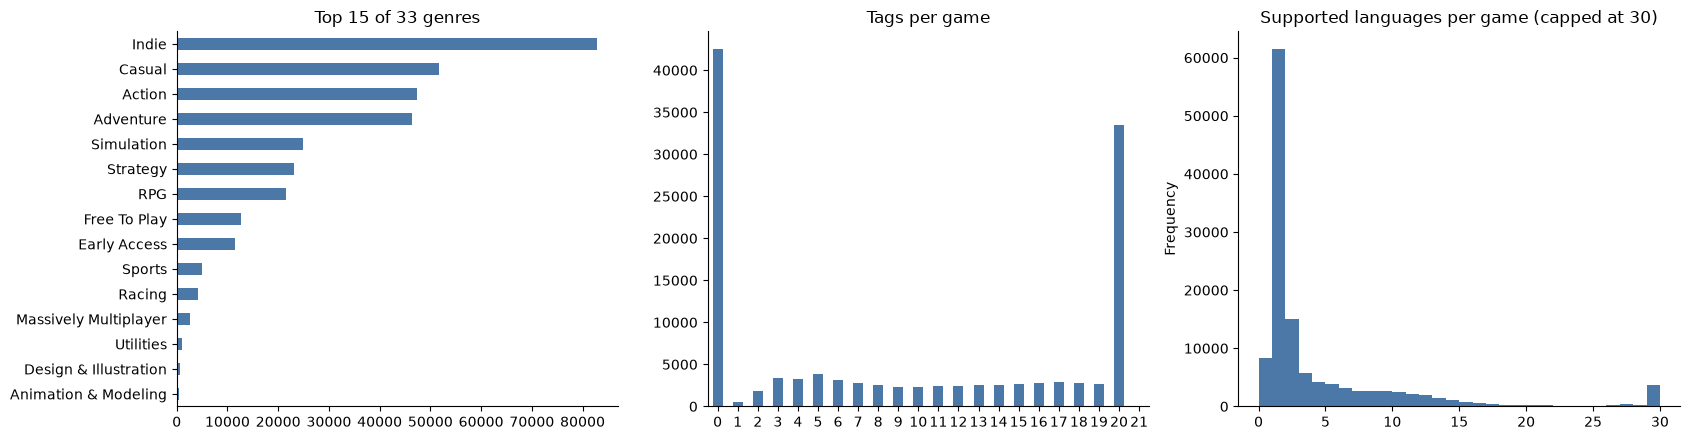

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
genre_counts = df["genre_list"].explode().value_counts()
genre_counts.head(15).sort_values().plot.barh(ax=axes[0], color=BLUE)
axes[0].set_title(f"Top 15 of {genre_counts.size} genres")
axes[0].set_ylabel("")
df["n_tags"].value_counts().sort_index().plot.bar(ax=axes[1], color=BLUE, rot=0)
axes[1].set_title("Tags per game")
axes[1].set_xlabel("")
df["n_languages"].clip(upper=30).plot.hist(ax=axes[2], bins=30, color=BLUE)
axes[2].set_title("Supported languages per game (capped at 30)")
plt.tight_layout()
plt.show()

## Relationships with the target


In [21]:
known = df[~df["no_owner_data"]].copy()
base_rate = known["hit"].mean()
print(f"Rows with owner data: {len(known):,}   overall hit rate: {base_rate:.1%}")

def hit_rate_bars(rates, ax, title, rotate=0):
    ax.bar([str(i) for i in rates.index], rates.values * 100, color=ORANGE)
    ax.axhline(base_rate * 100, color="gray", ls="--", lw=1)
    ax.set_title(title)
    ax.set_ylabel("hit rate (%)")
    ax.tick_params(axis="x", rotation=rotate)

Rows with owner data: 101,276   overall hit rate: 8.7%


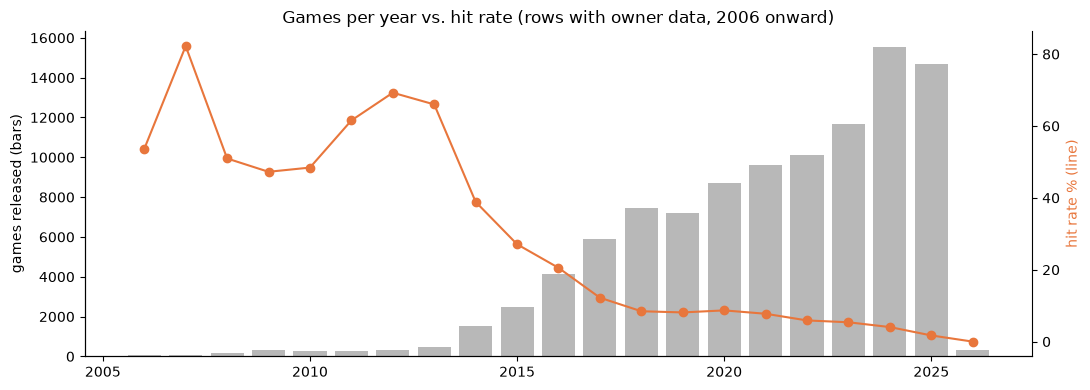

,hit %,games
release_year,,
2017,12.2,5903
2018,8.4,7434
2019,8.1,7226
2020,8.7,8725
2021,7.7,9613
2022,5.9,10096
2023,5.4,11671
2024,4.0,15548
2025,1.7,14680


In [22]:
years = known[known["release_year"] >= 2006].groupby("release_year")["hit"].agg(["mean", "size"])

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(years.index, years["size"], color=GRAY)
ax1.set_ylabel("games released (bars)")
ax2 = ax1.twinx()
ax2.plot(years.index, years["mean"] * 100, marker="o", color=ORANGE)
ax2.set_ylabel("hit rate % (line)", color=ORANGE)
ax2.spines["right"].set_visible(True)
ax1.set_title("Games per year vs. hit rate (rows with owner data, 2006 onward)")
plt.tight_layout()
plt.show()
years.tail(10).assign(mean=lambda t: (t["mean"] * 100).round(1)).rename(columns={"mean": "hit %", "size": "games"})

The hit rate falls steadily for newer games. Recent releases simply haven't had time to collect owners, which is a time effect rather than a quality signal.

### Launch-time features vs. hit rate

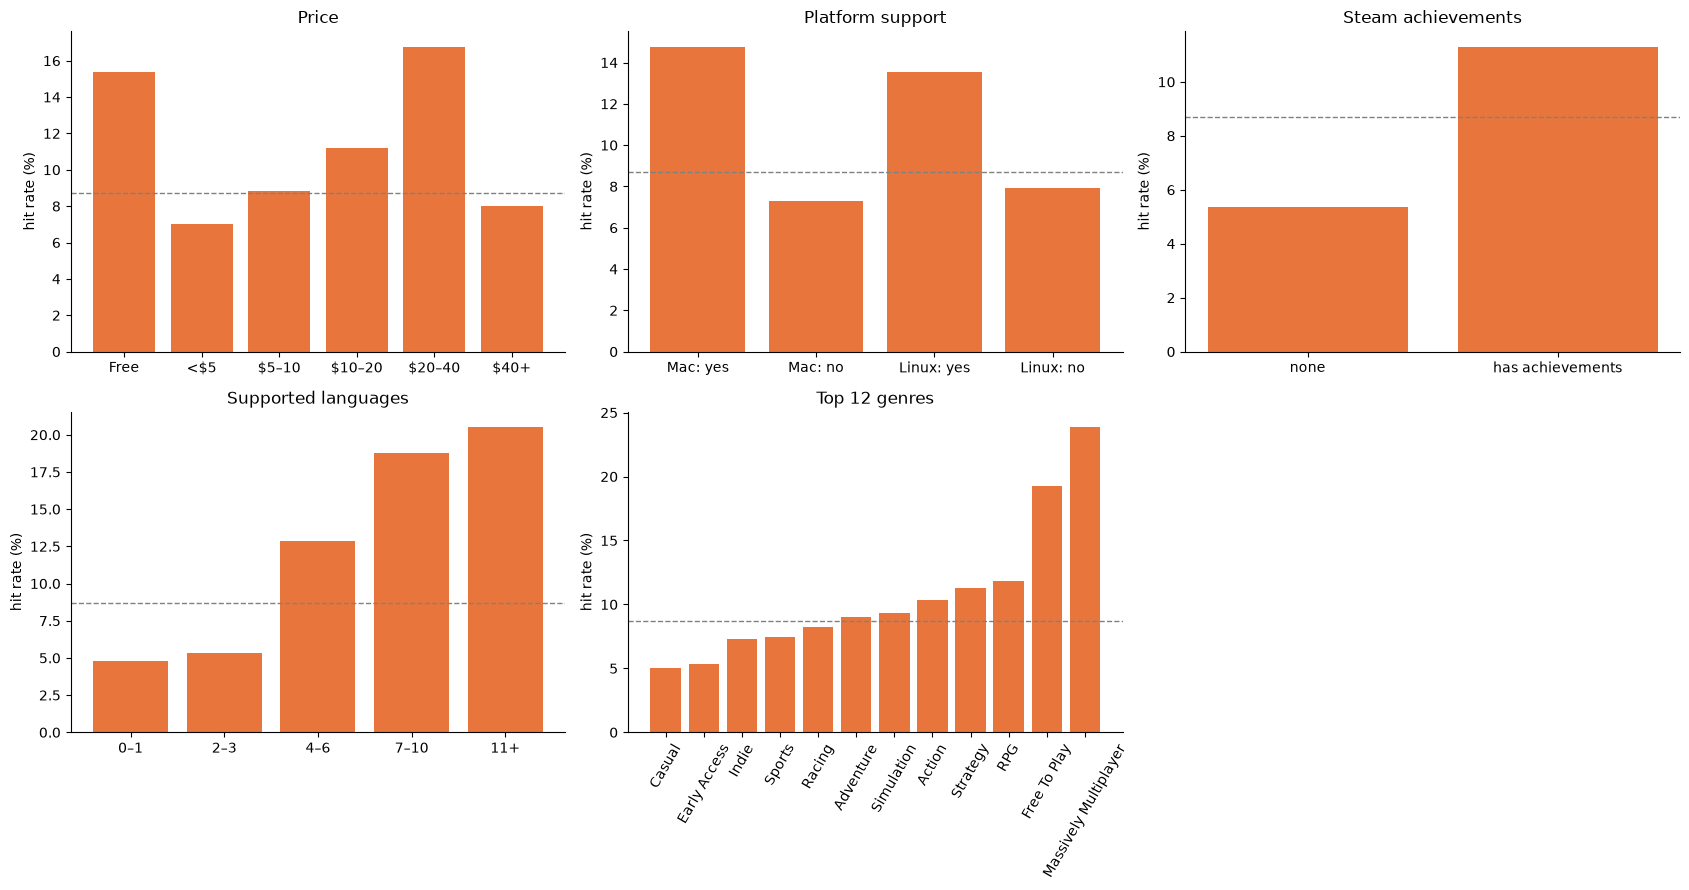

In [23]:
price_band = pd.cut(known["Price"], [-0.01, 0, 4.99, 9.99, 19.99, 39.99, np.inf],
                    labels=["Free", "<$5", "$5–10", "$10–20", "$20–40", "$40+"])
language_band = pd.cut(known["n_languages"], [-1, 1, 3, 6, 10, np.inf],
                       labels=["0–1", "2–3", "4–6", "7–10", "11+"])
platforms = pd.Series({
    "Mac: yes": known.loc[known["Mac"], "hit"].mean(),
    "Mac: no": known.loc[~known["Mac"], "hit"].mean(),
    "Linux: yes": known.loc[known["Linux"], "hit"].mean(),
    "Linux: no": known.loc[~known["Linux"], "hit"].mean(),
})
achievements = known.groupby(known["Achievements"] > 0)["hit"].mean().rename({True: "has achievements", False: "none"})
top_genres = known["genre_list"].explode().value_counts().head(12).index
genre_hits = (known[["genre_list", "hit"]].explode("genre_list")
              .query("genre_list in @top_genres").groupby("genre_list")["hit"].mean().sort_values())

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
hit_rate_bars(known.groupby(price_band, observed=True)["hit"].mean(), axes[0, 0], "Price")
hit_rate_bars(platforms, axes[0, 1], "Platform support")
hit_rate_bars(achievements, axes[0, 2], "Steam achievements")
hit_rate_bars(known.groupby(language_band, observed=True)["hit"].mean(), axes[1, 0], "Supported languages")
hit_rate_bars(genre_hits, axes[1, 1], "Top 12 genres", rotate=60)
axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

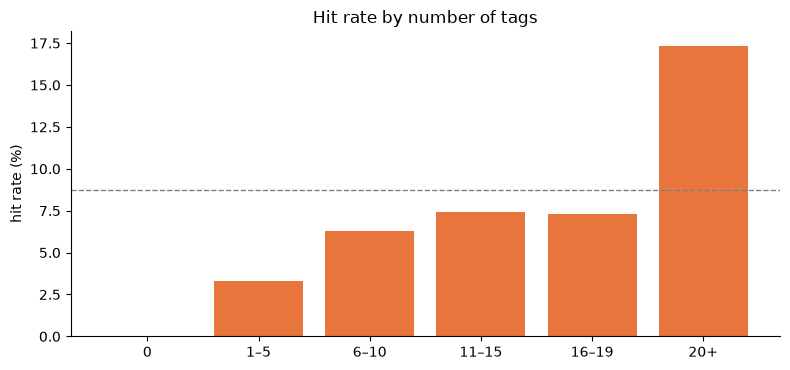

In [24]:
tag_band = pd.cut(known["n_tags"], [-1, 0, 5, 10, 15, 19, np.inf], labels=["0", "1–5", "6–10", "11–15", "16–19", "20+"])
fig, ax = plt.subplots(figsize=(8, 3.8))
hit_rate_bars(known.groupby(tag_band, observed=True)["hit"].mean(), ax, "Hit rate by number of tags")
plt.tight_layout()
plt.show()

Games with no tags are never hits, and games with 20 or more tags are hits about twice as often as
average. Players add tags on Steam, so the number of tags mostly measures how popular a game already is. That makes tag
count (and possibly the tags themselves) a likely leak. Worth raising under "Dataset suitability" in the meeting.


**Target**
- Hit = lower end of the owners range ≥ 100K (working cutoff). About 8.7% of games with owner data are hits, so the
  classes are imbalanced: use a stratified split, judge models by F1 / PR-AUC, and try class weights.
- Drop the `0 - 0` rows. They mean "no SteamSpy data", not "no owners", and include nearly all playtests.

**Features**
- Usable at launch: price, platforms, release year/month, genres and categories (one 0/1 column per label), number of
  languages, achievements, required age, developer/publisher history.
- Leave out the after-launch columns (reviews, recommendations, playtime, peak players, Metacritic / User score) and
  probably tags and tag count, since they leak popularity.
- Double-check `DLC count` and `Discount`, which were scraped in 2026 rather than at launch.
- Drop empty or near-empty columns (`Movies`, `Score rank`, `User score`) and the IDs, URLs and free text.

**Splitting**
- Strong time effect: keep only games that have had time to sell (for example, released by 2023) and/or split by
  release date.
- Many studios have several games: consider keeping each studio's games in a single split.